In [1]:
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.stats.multitest as smsm
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Experiment 1: $2^4$ Factorial

In [2]:
exp1 = pd.read_csv("RESULTS_THREEPPL_TotalUnitCount=11360_2026-01-22.csv")
exp1.head()

,Tile.Size,Prev.Delay,Prev.Type,Play.Some,Browse.Time
0,20,0,TT,Y,17.274400
1,20,0,TT,Y,19.096605
2,20,0,TT,Y,19.041734
3,20,0,TT,Y,19.145162
4,20,0,TT,Y,17.835171


In [3]:
# Convert to -1 and +1
exp1["A"] = (exp1["Tile.Size"] - (20 + 50) / 2) / ((50 - 20) / 2)
exp1["B"] = (exp1["Prev.Delay"] - (1 + 0) / 2) / ((1 - 0) / 2)
exp1["C"] = [-1 if x == "TT" else 1 for x in exp1["Prev.Type"]]
exp1["D"] = [-1 if x == "N" else 1 for x in exp1["Play.Some"]]
exp1["y"] = exp1["Browse.Time"]
exp1.head()

,Tile.Size,Prev.Delay,Prev.Type,Play.Some,Browse.Time,A,B,C,D,y
0,20,0,TT,Y,17.274400,-1.0,-1.0,-1,1,17.274400
1,20,0,TT,Y,19.096605,-1.0,-1.0,-1,1,19.096605
2,20,0,TT,Y,19.041734,-1.0,-1.0,-1,1,19.041734
3,20,0,TT,Y,19.145162,-1.0,-1.0,-1,1,19.145162
4,20,0,TT,Y,17.835171,-1.0,-1.0,-1,1,17.835171


In [4]:
# Checking std for sample size calculation
exp1.groupby(["A", "B", "C", "D"])["y"].std()

A     B     C   D 
-1.0  -1.0  -1  -1    1.095018
                 1    0.957708
             1  -1    0.962515
                 1    0.999437
       1.0  -1  -1    1.028681
                 1    1.011670
             1  -1    0.943927
                 1    1.012856
 1.0  -1.0  -1  -1    1.146070
                 1    1.029938
             1  -1    0.907603
                 1    0.971823
       1.0  -1  -1    0.968329
                 1    1.026025
             1  -1    1.040733
                 1    1.052719
Name: y, dtype: float64

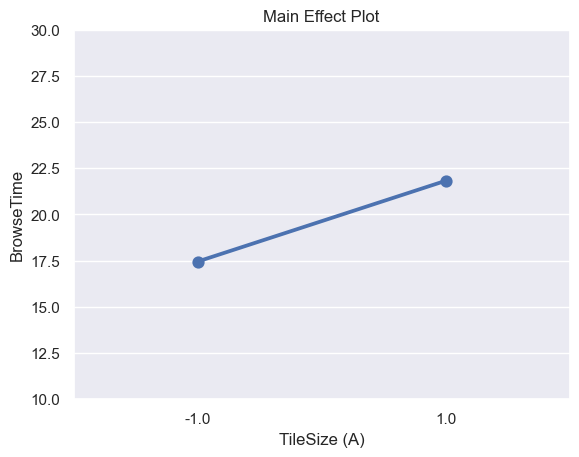

In [5]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="A", y="y", data=exp1)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("TileSize (A)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

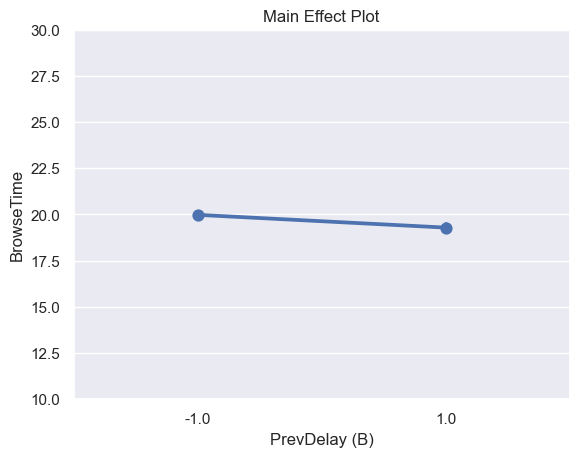

In [6]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="B", y="y", data=exp1)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("PrevDelay (B)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

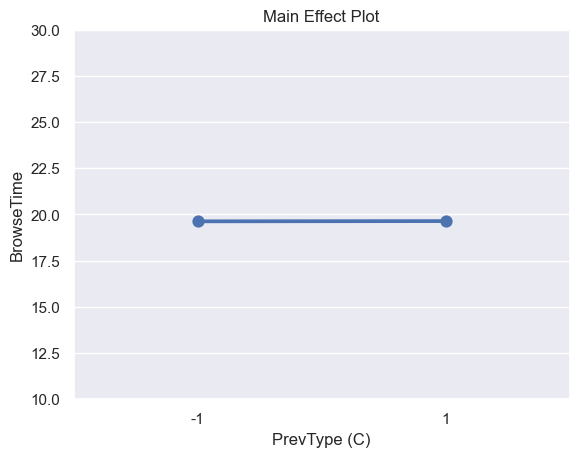

In [7]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="C", y="y", data=exp1)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("PrevType (C)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

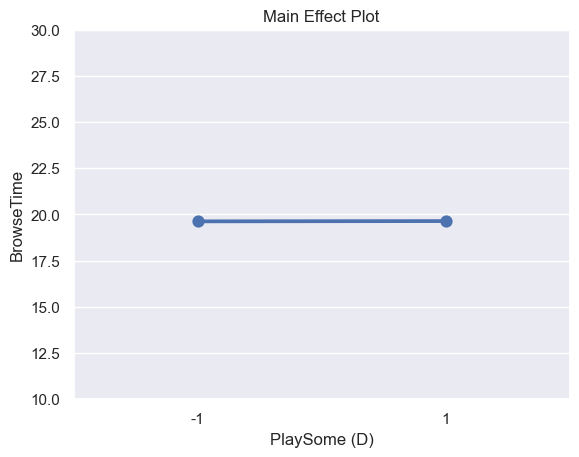

In [8]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="D", y="y", data=exp1)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("PlaySome (D)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

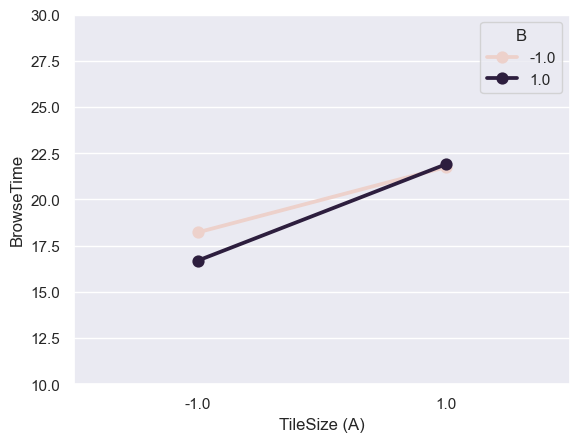

In [9]:
# Interaction between A and B
sns.set_theme(style="darkgrid")
fig12 = sns.pointplot(x="A", hue="B", y="y", data=exp1)
fig12.set_ylabel("BrowseTime")
fig12.set_xlabel("TileSize (A)")
fig12.set_ylim(10, 30)
plt.show()

## Partial F-tests

In [10]:
model = smf.ols("y ~ A * B * C * D", data=exp1).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.833
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     581.9
Date:                Wed, 21 Jan 2026   Prob (F-statistic):               0.00
Time:                        20:26:46   Log-Likelihood:                -2509.1
No. Observations:                1760   AIC:                             5050.
Df Residuals:                    1744   BIC:                             5138.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     19.6339      0.024    814.469      0.000      19.587      19.681
A              2.1847      0.024     90.626      0.000       2.137       2.232
B             -0.3446      0.024    -14.296      0.000      -0.392      -0.297
A:B            0.4206      0.024     17.448      0.000       0.373       0.468
C              0.0065      0.024      0.271      0.787      -0.041       0.054
A:C            0.0056      0.024      0.233      0.816      -0.042       0.053
B:C            0.0255      0.024      1.058      0.290      -0.022       0.073
A:B:C          0.0131      0.024      0.543      0.587      -0.034       0.060
D              0.0076      0.024      0.317      0.751      -0.040       0.055
A:D           -0.0431      0.024     -1.789      0.074      -0.090       0.004
B:D           -0.0035      0.024     -0.144      0.885      -0.051       0.044
A:B:D          0.0152      0.024      0.631      0.528      -0.032       0.062
C:D            0.0057      0.024      0.237      0.813      -0.042       0.053
A:C:D          0.0135      0.024      0.559      0.577      -0.034       0.061
B:C:D          0.0186      0.024      0.773      0.440      -0.029       0.066
A:B:C:D       -0.0202      0.024     -0.840      0.401      -0.068       0.027
==============================================================================
Omnibus:                        0.326   Durbin-Watson:                   1.984
Prob(Omnibus):                  0.849   Jarque-Bera (JB):                0.387
Skew:                           0.023   Prob(JB):                        0.824
Kurtosis:                       2.944   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

$H_0: \beta_{3}=\beta_{13}=\beta_{23}=\beta_{123}=\beta_{4}=\beta_{24}=\beta_{124}=\beta_{34}=\beta_{134}=\beta_{234}=\beta_{1234}=0$, (1=A, 2=B, 3=C, 4=D)

In [11]:
model_red1 = smf.ols("y ~ A + B + A:B + A:D", data=exp1).fit()
sm.stats.anova_lm(model_red1, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1755.0,1787.523479,0.0,NaN,NaN,NaN
1,1744.0,1783.706202,11.0,3.817278,0.3393,0.976966


Fail to reject $H_0$

$H_0:\beta_{14}=0$

In [12]:
model_red2 = smf.ols("y ~ A + B + A:B", data=exp1).fit()
sm.stats.anova_lm(model_red2, model_red1)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1756.0,1790.797871,0.0,NaN,NaN,NaN
1,1755.0,1787.523479,1.0,3.274392,3.214815,0.073147


Fail to reject $H_0$ at 5% significance level but reject $H_0$ at 10% significance level -> revisit this later (rejecting $H_0$ means A:D is significant)

$H_0:\beta_{12}=0$

In [13]:
model_red3 = smf.ols("y ~ A + B", data=exp1).fit()
sm.stats.anova_lm(model_red3, model_red2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1757.0,2102.152642,0.0,NaN,NaN,NaN
1,1756.0,1790.797871,1.0,311.354771,305.304683,3.703303e-63


Reject $H_0$ -> A:B is significant

$H_0:\beta_{1}=0$

In [14]:
model_red4 = smf.ols("y ~ B", data=exp1).fit()
sm.stats.anova_lm(model_red4, model_red3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1758.0,10502.264286,0.0,NaN,NaN,NaN
1,1757.0,2102.152642,1.0,8400.111645,7020.896517,0.0


Reject $H_0$ -> A is significant

$H_0:\beta_{2}=0$

In [15]:
model_red5 = smf.ols("y ~ A", data=exp1).fit()
sm.stats.anova_lm(model_red5, model_red3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1758.0,2311.194745,0.0,NaN,NaN,NaN
1,1757.0,2102.152642,1.0,209.042103,174.71946,4.255843e-38


Reject $H_0$ -> B is significant

# Experiment 2: Factorial TileSize:PrevDelay

In [16]:
exp2 = pd.read_csv("RESULTS_THREEPPL_TotalUnitCount=12610_2026-01-22.csv")
exp2.columns = ["TileSize", "PrevDelay", "PrevType", "PlaySome", "BrowseTime"]
exp2.head()

,TileSize,PrevDelay,PrevType,PlaySome,BrowseTime
0,20,0.0,TT,N,19.092245
1,20,0.0,TT,N,17.560572
2,20,0.0,TT,N,18.336584
3,20,0.0,TT,N,17.657747
4,20,0.0,TT,N,20.151146


In [17]:
# Checking std for sample size calculation
exp2.groupby(["TileSize", "PrevDelay", "PrevType", "PlaySome"])["BrowseTime"].std()

TileSize  PrevDelay  PrevType  PlaySome
10        0.0        TT        N           0.981871
          0.5        TT        N           1.016277
          1.0        TT        N           0.942785
          1.5        TT        N           1.048629
          2.0        TT        N           1.142361
20        0.0        TT        N           1.093461
          0.5        TT        N           0.957867
          1.0        TT        N           0.934089
          1.5        TT        N           0.907828
          2.0        TT        N           0.867239
30        0.0        TT        N           0.925142
          0.5        TT        N           1.099651
          1.0        TT        N           1.178946
          1.5        TT        N           0.838299
          2.0        TT        N           1.164767
40        0.0        TT        N           0.994266
          0.5        TT        N           0.920533
          1.0        TT        N           1.021890
          1.5        TT 

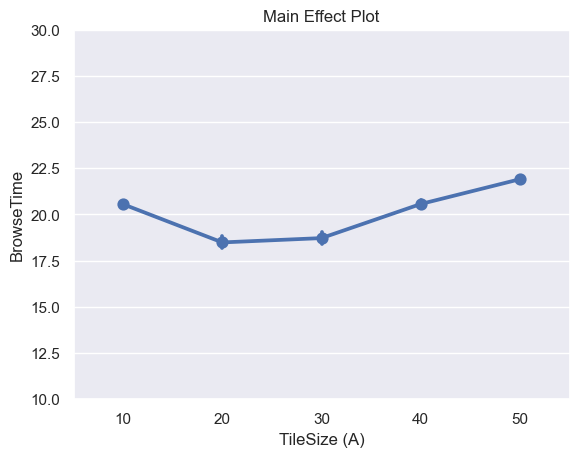

In [18]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="TileSize", y="BrowseTime", data=exp2)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("TileSize (A)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

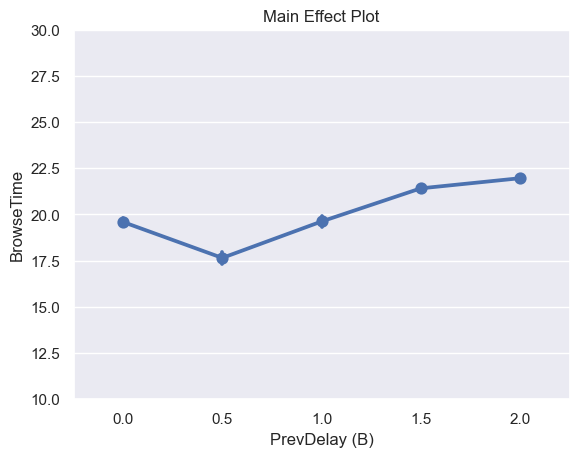

In [19]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="PrevDelay", y="BrowseTime", data=exp2)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("PrevDelay (B)")
figB.set_ylim(10, 30)
figB.set_title("Main Effect Plot")
plt.show()

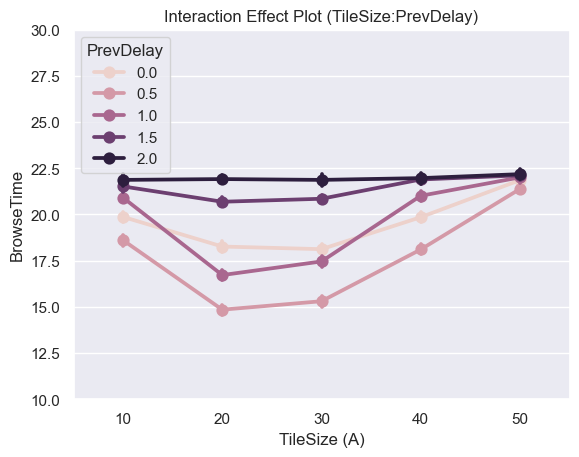

In [20]:
figAB = sns.pointplot(x="TileSize", hue="PrevDelay", y="BrowseTime", data=exp2)
figAB.set_ylabel("BrowseTime")
figAB.set_xlabel("TileSize (A)")
figAB.set_ylim(10, 30)
figAB.set_title("Interaction Effect Plot (TileSize:PrevDelay)")
plt.show()

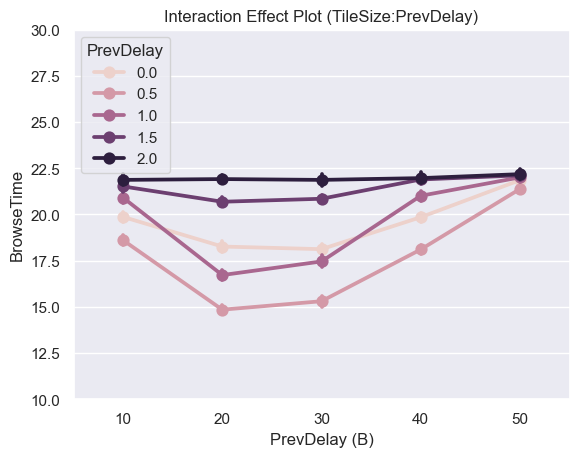

In [21]:
figAB = sns.pointplot(x="TileSize", hue="PrevDelay", y="BrowseTime", data=exp2)
figAB.set_ylabel("BrowseTime")
figAB.set_xlabel("PrevDelay (B)")
figAB.set_ylim(10, 30)
figAB.set_title("Interaction Effect Plot (TileSize:PrevDelay)")
plt.show()

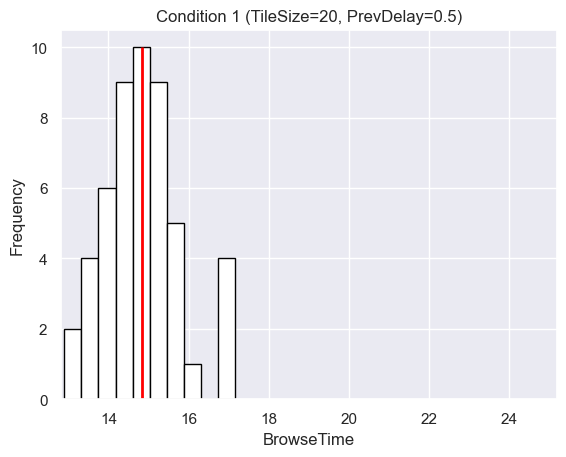

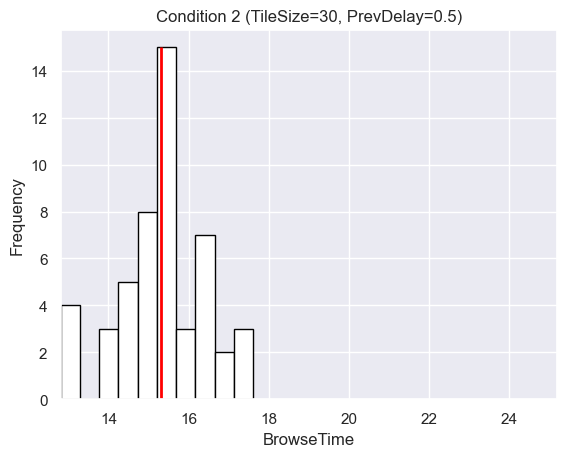

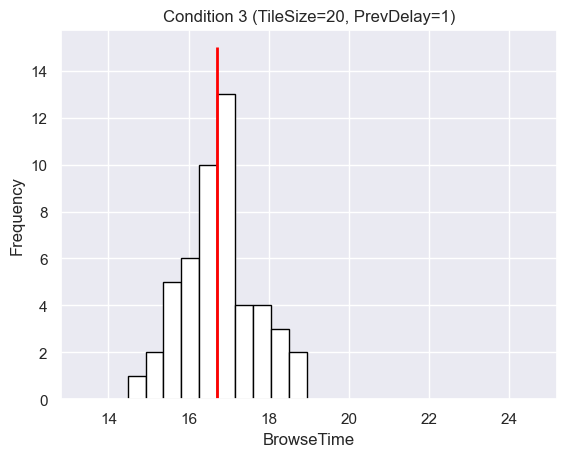

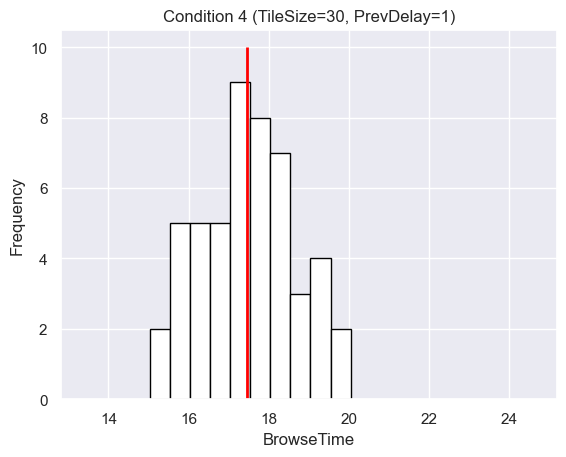

In [22]:
cond1 = exp2["BrowseTime"][(exp2["TileSize"] == 20) & (exp2["PrevDelay"] == 0.5)]
cond2 = exp2["BrowseTime"][(exp2["TileSize"] == 30) & (exp2["PrevDelay"] == 0.5)]
cond3 = exp2["BrowseTime"][(exp2["TileSize"] == 20) & (exp2["PrevDelay"] == 1)]
cond4 = exp2["BrowseTime"][(exp2["TileSize"] == 30) & (exp2["PrevDelay"] == 1)]
xmin = min(exp2["BrowseTime"])
xmax = max(exp2["BrowseTime"])
plt.figure()
plt.hist(cond1, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 1 (TileSize=20, PrevDelay=0.5)")
plt.vlines(x=np.mean(cond1), ymin=0, ymax=10, color="red", linewidth=2)
plt.figure()
plt.hist(cond2, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 2 (TileSize=30, PrevDelay=0.5)")
plt.vlines(x=np.mean(cond2), ymin=0, ymax=15, color="red", linewidth=2)
plt.figure()
plt.hist(cond3, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 3 (TileSize=20, PrevDelay=1)")
plt.vlines(x=np.mean(cond3), ymin=0, ymax=15, color="red", linewidth=2)
plt.figure()
plt.hist(cond4, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 4 (TileSize=30, PrevDelay=1)")
plt.vlines(x=np.mean(cond4), ymin=0, ymax=10, color="red", linewidth=2)
plt.show()

## t-tests

Distributions look roughly normal -> t-test is appropriate

In [23]:
# Test for equality of variances
t = np.var(cond1, ddof=1) / np.var(cond2, ddof=1)
print("t =", t)

t = 0.7587536604513336


In [24]:
pv = (
    stats.f.cdf(t, dfn=len(cond1) - 1, dfd=len(cond2) - 1)
    + 1
    - stats.f.cdf(1 / t, dfn=len(cond1) - 1, dfd=len(cond2) - 1)
)
print("p-value =", pv)

p-value = 0.337133670512225


$H_0: \mu_1=\mu_2$ vs. $H_A: \mu_1\ne\mu_2$

In [25]:
# Fail to reject H_0 -> equal_var=True (Student's t-test)
t, pv1 = stats.ttest_ind(cond1, cond2, equal_var=True, alternative="two-sided")
print("t =", t)
print("p-value =", pv1)

t = -2.220380259844362
p-value = 0.028696820941580107


In [26]:
# Test for equality of variances
t = np.var(cond2, ddof=1) / np.var(cond3, ddof=1)
print("t =", t)

t = 1.3859054215050923


In [27]:
pv = (
    1
    - stats.f.cdf(t, dfn=len(cond2) - 1, dfd=len(cond3) - 1)
    + stats.f.cdf(1 / t, dfn=len(cond2) - 1, dfd=len(cond3) - 1)
)
print("p-value =", pv)

p-value = 0.25682323553435316


$H_0: \mu_2\ge\mu_3$ vs. $H_A: \mu_2<\mu_3$

In [28]:
t, pv2 = stats.ttest_ind(cond2, cond3, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv2)

t = -6.931721607230541
p-value = 2.2224085445528795e-10


In [29]:
# Test for equality of variances
t = np.var(cond1, ddof=1) / np.var(cond3, ddof=1)
print("t =", t)

t = 1.0515608116063373


In [30]:
pv = (
    1
    - stats.f.cdf(t, dfn=len(cond1) - 1, dfd=len(cond3) - 1)
    + stats.f.cdf(1 / t, dfn=len(cond1) - 1, dfd=len(cond3) - 1)
)
print("p-value =", pv)

p-value = 0.861032631670009


$H_0: \mu_1\ge\mu_3$ vs. $H_A: \mu_1<\mu_3$

In [31]:
t, pv3 = stats.ttest_ind(cond1, cond3, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv3)

t = -9.895464522684078
p-value = 1.0203326357537792e-16


In [32]:
# Test for equality of variances
t = np.var(cond2, ddof=1) / np.var(cond4, ddof=1)
print("t =", t)

t = 0.8700053109947388


In [33]:
pv = (
    stats.f.cdf(t, dfn=len(cond2) - 1, dfd=len(cond4) - 1)
    + 1
    - stats.f.cdf(1 / t, dfn=len(cond2) - 1, dfd=len(cond4) - 1)
)
print("p-value =", pv)

p-value = 0.6278742863433542


$H_0: \mu_1\ge\mu_3$ vs. $H_A: \mu_1<\mu_3$

In [34]:
t, pv4 = stats.ttest_ind(cond2, cond4, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv4)

t = -9.440164126123785
p-value = 9.935161836346503e-16


In [35]:
# Test for equality of variances
t = np.var(cond1, ddof=1) / np.var(cond4, ddof=1)
print("t =", t)

t = 0.6601197143293589


In [36]:
pv = (
    stats.f.cdf(t, dfn=len(cond1) - 1, dfd=len(cond4) - 1)
    + 1
    - stats.f.cdf(1 / t, dfn=len(cond1) - 1, dfd=len(cond4) - 1)
)
print("p-value =", pv)

p-value = 0.14954211011078744


$H_0: \mu_1\ge\mu_4$ vs. $H_A: \mu_1<\mu_4$

In [37]:
t, pv5 = stats.ttest_ind(cond1, cond4, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv5)

t = -12.15083442830238
p-value = 1.4357519798134469e-21


In [38]:
p = [pv1, pv2, pv3, pv4, pv5]
res, padj, alphSid, alphBonf = smsm.multipletests(
    pvals=p, alpha=0.01, method="bonferroni"
)
print("Should I reject H0? ", res)
print("The adjusted p-values are: ", padj)

Should I reject H0?  [False  True  True  True  True]
The adjusted p-values are:  [1.43484105e-01 1.11120427e-09 5.10166318e-16 4.96758092e-15
 7.17875990e-21]


# Experiment 3: Factorial TileSize:PrevDelay:PlaySome

In [39]:
exp3 = pd.read_csv("RESULTS_THREEPPL_TotalUnitCount=10800_2026-01-22.csv")
exp3.columns = ["TileSize", "PrevDelay", "PrevType", "PlaySome", "BrowseTime"]
exp3.head()

,TileSize,PrevDelay,PrevType,PlaySome,BrowseTime
0,20,0.5,TT,Y,15.066682
1,20,0.5,TT,Y,14.801437
2,20,0.5,TT,Y,15.521018
3,20,0.5,TT,Y,15.359749
4,20,0.5,TT,Y,15.698443


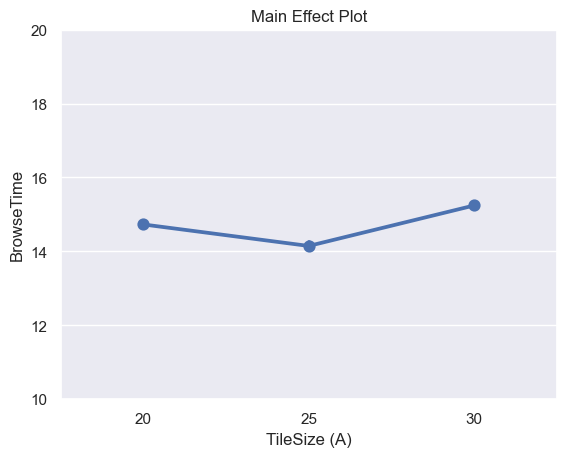

In [40]:
sns.set_theme(style="darkgrid")
figB = sns.pointplot(x="TileSize", y="BrowseTime", data=exp3)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("TileSize (A)")
figB.set_ylim(10, 20)
figB.set_title("Main Effect Plot")
plt.show()

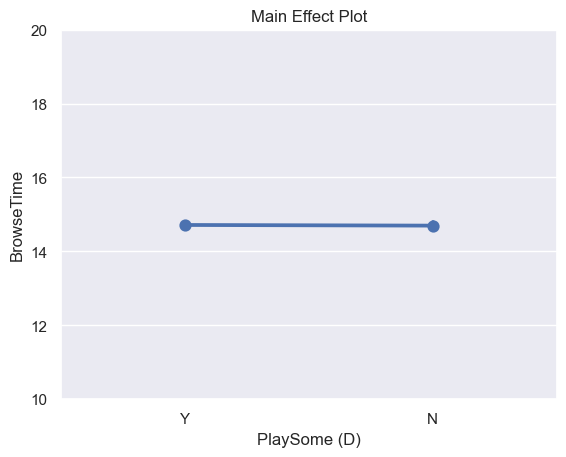

In [41]:
figB = sns.pointplot(x="PlaySome", y="BrowseTime", data=exp3)
figB.set_ylabel("BrowseTime")
figB.set_xlabel("PlaySome (D)")
figB.set_ylim(10, 20)
figB.set_title("Main Effect Plot")
plt.show()

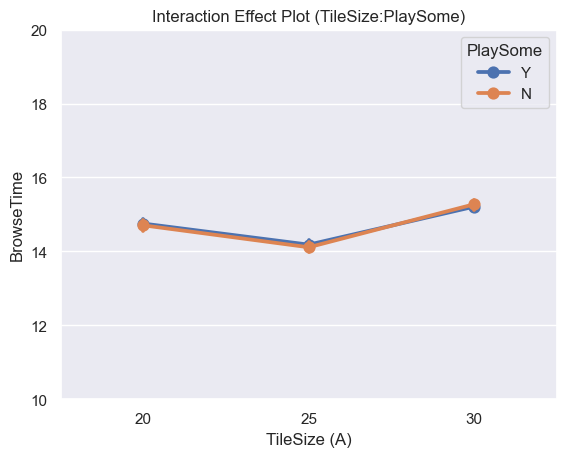

In [42]:
figCD = sns.pointplot(x="TileSize", hue="PlaySome", y="BrowseTime", data=exp3)
figCD.set_ylabel("BrowseTime")
figCD.set_xlabel("TileSize (A)")
figCD.set_ylim(10, 20)
figCD.set_title("Interaction Effect Plot (TileSize:PlaySome)")
plt.show()

## Partial F-tests

Full model: $\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3 + \beta_4 x_1x_3 + \beta_5 x_2x_3$

In [43]:
model = smf.ols("BrowseTime ~ C(TileSize) * C(PlaySome)", data=exp3).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             BrowseTime   R-squared:                       0.172
Model:                            OLS   Adj. R-squared:                  0.168
Method:                 Least Squares   F-statistic:                     49.48
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           1.19e-46
Time:                        20:26:47   Log-Likelihood:                -1684.5
No. Observations:                1200   AIC:                             3381.
Df Residuals:                    1194   BIC:                             3412.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                             14.7058      0.070    210.626      0.000      14.569      14.843
C(TileSize)[T.25]                     -0.5935      0.099     -6.010      0.000      -0.787      -0.400
C(TileSize)[T.30]                      0.5693      0.099      5.765      0.000       0.376       0.763
C(PlaySome)[T.Y]                       0.0469      0.099      0.475      0.635      -0.147       0.241
C(TileSize)[T.25]:C(PlaySome)[T.Y]     0.0241      0.140      0.173      0.863      -0.250       0.298
C(TileSize)[T.30]:C(PlaySome)[T.Y]    -0.1116      0.140     -0.799      0.424      -0.386       0.162
==============================================================================
Omnibus:                        3.061   Durbin-Watson:                   1.903
Prob(Omnibus):                  0.216   Jarque-Bera (JB):                3.102
Skew:                          -0.106   Prob(JB):                        0.212
Kurtosis:                       2.868   Cond. No.                         9.77
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

$H_0:\beta_{4}=\beta_5=0$

In [44]:
model_red1 = smf.ols("BrowseTime ~ C(TileSize) + C(PlaySome)", data=exp3).fit()
sm.stats.anova_lm(model_red1, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1196.0,1165.140686,0.0,NaN,NaN,NaN
1,1194.0,1164.092098,2.0,1.048588,0.537764,0.584194


TileSize:PlaySome not significant

$H_0:\beta_{3}=0$

In [45]:
model_red2 = smf.ols("BrowseTime ~ C(TileSize)", data=exp3).fit()
sm.stats.anova_lm(model_red2, model_red1)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,1197.0,1165.234586,0.0,NaN,NaN,NaN
1,1196.0,1165.140686,1.0,0.0939,0.096387,0.756263


PlaySome does not have signifcant main effect

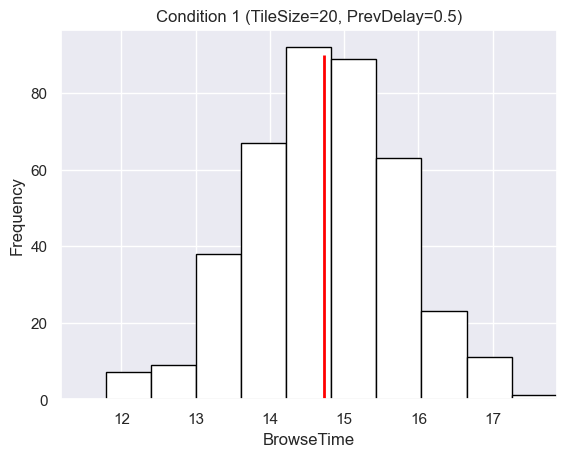

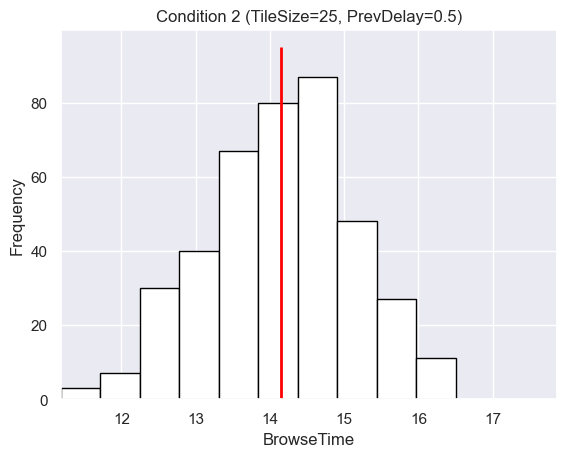

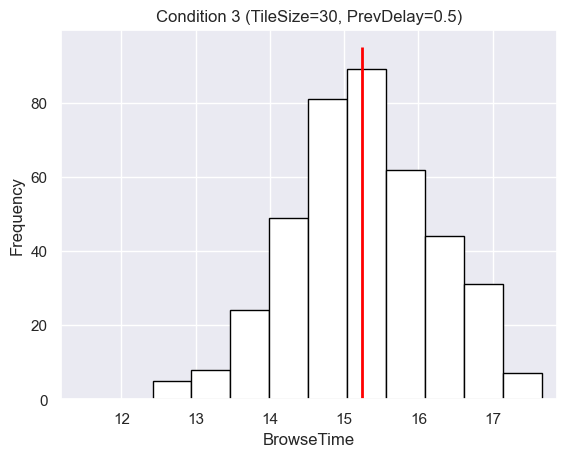

In [46]:
cond1 = exp3["BrowseTime"][(exp3["TileSize"] == 20) & (exp3["PrevDelay"] == 0.5)]
cond2 = exp3["BrowseTime"][(exp3["TileSize"] == 25) & (exp3["PrevDelay"] == 0.5)]
cond3 = exp3["BrowseTime"][(exp3["TileSize"] == 30) & (exp3["PrevDelay"] == 0.5)]
xmin = min(exp3["BrowseTime"])
xmax = max(exp3["BrowseTime"])
plt.figure()
plt.hist(cond1, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 1 (TileSize=20, PrevDelay=0.5)")
plt.vlines(x=np.mean(cond1), ymin=0, ymax=90, color="red", linewidth=2)
plt.figure()
plt.hist(cond2, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 2 (TileSize=25, PrevDelay=0.5)")
plt.vlines(x=np.mean(cond2), ymin=0, ymax=95, color="red", linewidth=2)
plt.figure()
plt.hist(cond3, color="white", edgecolor="black")
plt.xlim(xmin, xmax)
plt.xlabel("BrowseTime")
plt.ylabel("Frequency")
plt.title("Condition 3 (TileSize=30, PrevDelay=0.5)")
plt.vlines(x=np.mean(cond3), ymin=0, ymax=95, color="red", linewidth=2)

The distributions look roughly normal -> use t-test

## t-tests

In [47]:
t = np.var(cond1, ddof=1) / np.var(cond2, ddof=1)
print("t =", t)

t = 1.0624400803356746


In [48]:
pv = (
    1
    - stats.f.cdf(t, dfn=len(cond1) - 1, dfd=len(cond2) - 1)
    + stats.f.cdf(1 / t, dfn=len(cond1) - 1, dfd=len(cond2) - 1)
)
print("p-value =", pv)

p-value = 0.5455115322616144


$H_0: \mu_1\le\mu_2$ vs. $H_A: \mu_1>\mu_2$

In [49]:
t, pv1 = stats.ttest_ind(cond1, cond2, equal_var=True, alternative="greater")
print("t =", t)
print("p-value =", pv1)

t = 8.224149503384153
p-value = 3.9755977579092514e-16


In [50]:
t = np.var(cond2, ddof=1) / np.var(cond3, ddof=1)
print("t =", t)

t = 1.0523193353716649


In [51]:
pv = (
    1
    - stats.f.cdf(t, dfn=len(cond2) - 1, dfd=len(cond3) - 1)
    + stats.f.cdf(1 / t, dfn=len(cond2) - 1, dfd=len(cond3) - 1)
)
print("p-value =", pv)

p-value = 0.6107650173736008


$H_0: \mu_2\ge\mu_3$ vs. $H_A: \mu_2<\mu_3$

In [52]:
t, pv2 = stats.ttest_ind(cond2, cond3, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv2)

t = -15.926157543176018
p-value = 4.27243318554776e-50


In [53]:
t = np.var(cond1, ddof=1) / np.var(cond3, ddof=1)
print("t =", t)

t = 1.1180262392110554


In [54]:
pv = (
    1
    - stats.f.cdf(t, dfn=len(cond1) - 1, dfd=len(cond3) - 1)
    + stats.f.cdf(1 / t, dfn=len(cond1) - 1, dfd=len(cond3) - 1)
)
print("p-value =", pv)

p-value = 0.26559390116778203


$H_0: \mu_1\ge\mu_3$ vs. $H_A: \mu_1<\mu_3$

In [55]:
t, pv3 = stats.ttest_ind(cond1, cond3, equal_var=True, alternative="less")
print("t =", t)
print("p-value =", pv3)

t = -7.3520690231801025
p-value = 2.420547203816075e-13


In [56]:
p = [pv1, pv2, pv3]
res, padj, alphSid, alphBonf = smsm.multipletests(
    pvals=p, alpha=0.01, method="bonferroni"
)
print("Should I reject H0? ", res)
print("The adjusted p-values are: ", padj)

Should I reject H0?  [ True  True  True]
The adjusted p-values are:  [1.19267933e-15 1.28172996e-49 7.26164161e-13]


We conclude that $\mu_2$ is the smallest, so Condition 2 (TileSize=25, PrevDelay=0.5) is optimal